In [2]:

import os

train_path = "../data/raw/archive/Train"
val_path = "../data/raw/archive/Val"

classes = os.listdir(train_path)

print("Classes:", classes)


Classes: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


In [3]:
print("Training Dataset:")

for classe in classes:
    folder = os.path.join(train_path, classe, "images")

    images = os.listdir(folder)

    print(classe, ":", len(images))


Training Dataset:
Glioma : 1153
Meningioma : 1449
No Tumor : 711
Pituitary : 1424


In [4]:
print("Validation Dataset:")

for classe in classes:
    folder = os.path.join(val_path, classe, "images")

    images = os.listdir(folder)

    print(classe, ":", len(images))


Validation Dataset:
Glioma : 136
Meningioma : 140
No Tumor : 100
Pituitary : 136


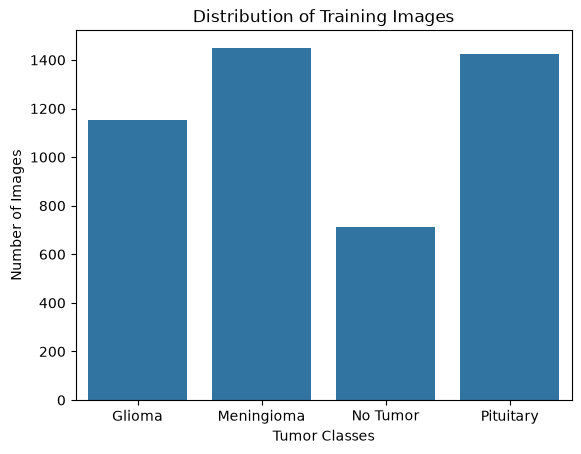

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

labels = []

for classe in classes:
    folder = os.path.join(train_path, classe, "images")

    for image in os.listdir(folder):
        if image.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
            labels.append(classe)

sns.countplot(x=labels)

plt.title("Distribution of Training Images")
plt.xlabel("Tumor Classes")
plt.ylabel("Number of Images")
plt.show()


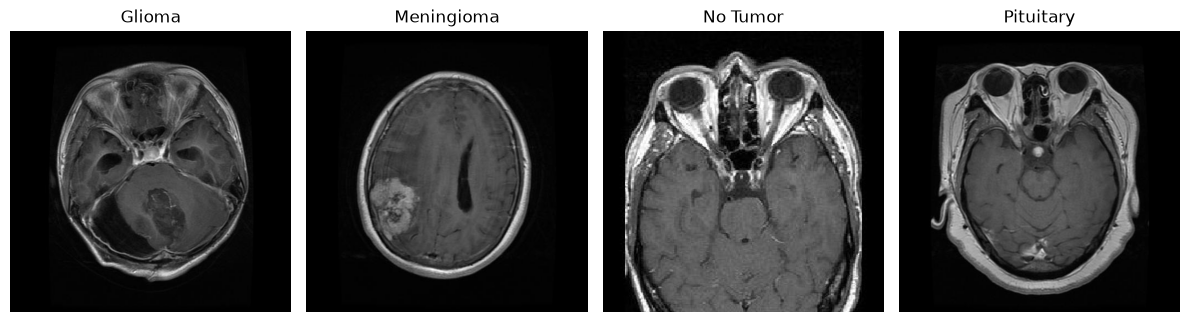

In [6]:
from PIL import Image

plt.figure(figsize=(12, 4))

for i, classe in enumerate(classes):

    folder = os.path.join(train_path, classe, "images")

    images = os.listdir(folder)
    image_path = os.path.join(folder, images[0])

    image = Image.open(image_path)

    plt.subplot(1, 4, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(classe)
    plt.axis("off")

plt.tight_layout()
plt.savefig("mri_class_samples.png")
plt.show()


In [7]:
extensions = (".jpg", ".jpeg", ".png", ".bmp")

for dataset_path in [train_path, val_path]:

    print("\nDataset:", dataset_path)

    for classe in classes:

        folder = os.path.join(dataset_path, classe, "images")

        valid = 0
        invalid = 0

        for filename in os.listdir(folder):

            file_path = os.path.join(folder, filename)

            if not os.path.isfile(file_path):
                continue

            if not filename.lower().endswith(extensions):
                invalid += 1
                print("Invalid extension:", filename)
                continue

            try:
                with Image.open(file_path) as image:
                    image.load()

                valid += 1

            except (OSError, ValueError):
                invalid += 1
                print("Corrupted image:", filename)

        print(classe, "- Valid:", valid, "- Invalid:", invalid)



Dataset: ../data/raw/archive/Train
Glioma - Valid: 1153 - Invalid: 0
Meningioma - Valid: 1449 - Invalid: 0
No Tumor - Valid: 711 - Invalid: 0
Pituitary - Valid: 1424 - Invalid: 0

Dataset: ../data/raw/archive/Val
Glioma - Valid: 136 - Invalid: 0
Meningioma - Valid: 140 - Invalid: 0
No Tumor - Valid: 100 - Invalid: 0
Pituitary - Valid: 136 - Invalid: 0


In [8]:
for dataset_path in [train_path, val_path]:

    print("\nDataset:", dataset_path)

    for classe in classes:

        images_folder = os.path.join(dataset_path, classe, "images")
        labels_folder = os.path.join(dataset_path, classe, "labels")

        images = os.listdir(images_folder)
        labels = os.listdir(labels_folder)

        image_names = set()

        for image in images:
            name = os.path.splitext(image)[0]
            image_names.add(name)

        label_names = set()

        for label in labels:
            if label.endswith(".txt"):
                name = os.path.splitext(label)[0]
                label_names.add(name)

        matched = image_names & label_names
        missing = image_names - label_names
        extra = label_names - image_names

        print(classe)
        print("Matched:", len(matched))
        print("Images without labels:", len(missing))
        print("Labels without images:", len(extra))



Dataset: ../data/raw/archive/Train
Glioma
Matched: 1153
Images without labels: 0
Labels without images: 0
Meningioma
Matched: 1449
Images without labels: 0
Labels without images: 0
No Tumor
Matched: 711
Images without labels: 0
Labels without images: 0
Pituitary
Matched: 1424
Images without labels: 0
Labels without images: 0

Dataset: ../data/raw/archive/Val
Glioma
Matched: 136
Images without labels: 0
Labels without images: 0
Meningioma
Matched: 140
Images without labels: 0
Labels without images: 0
No Tumor
Matched: 98
Images without labels: 2
Labels without images: 2
Pituitary
Matched: 136
Images without labels: 0
Labels without images: 0


In [9]:
for classe in classes:

    folder = os.path.join(train_path, classe, "labels")

    files = os.listdir(folder)

    print("\nClass:", classe)

    for filename in files:

        if filename.endswith(".txt"):

            path = os.path.join(folder, filename)

            with open(path, "r") as file:
                content = file.read()

            print("Filename:", filename)
            print("Content:", content)

            break



Class: Glioma
Filename: Te-glTr_0000.txt
Content: 0 0.555664 0.653320 0.146484 0.193359


Class: Meningioma
Filename: Tr-meTr_0008.txt
Content: 1 0.313477 0.631836 0.193359 0.240234


Class: No Tumor
Filename: 1.txt
Content: 2 0.502857 0.675714 0.851429 0.648571


Class: Pituitary
Filename: Te-pi_0010.txt
Content: 3 0.494141 0.431641 0.046875 0.039062



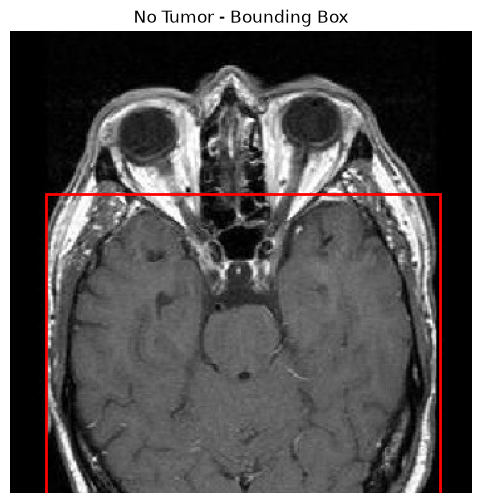

In [10]:
from PIL import Image
from matplotlib.patches import Rectangle

classe = "No Tumor"
filename = "1"

image_folder = os.path.join(train_path, classe, "images")
label_path = os.path.join(train_path, classe, "labels", filename + ".txt")

# Find the matching image
image_path = None

for image_name in os.listdir(image_folder):
    name = os.path.splitext(image_name)[0]

    if name == filename:
        image_path = os.path.join(image_folder, image_name)
        break

# Open the image
image = Image.open(image_path)
width, height = image.size

# Read the annotation
with open(label_path, "r") as file:
    values = file.readline().split()

class_id = int(values[0])
x, y, w, h = map(float, values[1:])

# Convert normalized values into pixels
box_width = w * width
box_height = h * height

x_min = (x * width) - box_width / 2
y_min = (y * height) - box_height / 2

# Display the image
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(image, cmap="gray")

box = Rectangle(
    (x_min, y_min),
    box_width,
    box_height,
    fill=False,
    edgecolor="red",
    linewidth=2
)

ax.add_patch(box)
ax.set_title("No Tumor - Bounding Box")
ax.axis("off")

plt.show()


In [11]:
for dataset_path in [train_path, val_path]:

    folder = os.path.join(dataset_path, "No Tumor", "labels")

    empty = 0
    not_empty = 0

    for filename in os.listdir(folder):

        if filename.endswith(".txt"):

            path = os.path.join(folder, filename)

            with open(path, "r") as file:
                content = file.read().strip()

            if content == "":
                empty += 1
            else:
                not_empty += 1

    print("\nDataset:", dataset_path)
    print("Empty annotations:", empty)
    print("Non-empty annotations:", not_empty)



Dataset: ../data/raw/archive/Train
Empty annotations: 0
Non-empty annotations: 711

Dataset: ../data/raw/archive/Val
Empty annotations: 0
Non-empty annotations: 100


In [12]:

valid = 0
invalid = 0

for dataset_path in [train_path, val_path]:
    for classe in classes:

        folder = os.path.join(dataset_path, classe, "labels")

        for filename in os.listdir(folder):

            if not filename.endswith(".txt"):
                continue

            path = os.path.join(folder, filename)

            with open(path, "r") as file:
                lines = file.readlines()

            for line in lines:

                values = line.split()

                try:
                    if len(values) != 5:
                        raise ValueError("Wrong number of values")

                    class_id = int(values[0])
                    x, y, w, h = map(float, values[1:])

                    if class_id not in [0, 1, 2, 3]:
                        raise ValueError("Invalid class ID")

                    if not (0 <= x <= 1 and 0 <= y <= 1):
                        raise ValueError("Invalid center")

                    if not (0 < w <= 1 and 0 < h <= 1):
                        raise ValueError("Invalid box size")

                    if x - w / 2 < -0.00001 or x + w / 2 > 1.00001:
                        raise ValueError("Box outside image")

                    if y - h / 2 < -0.00001 or y + h / 2 > 1.00001:
                        raise ValueError("Box outside image")

                    valid += 1

                except ValueError as error:
                    invalid += 1
                    print("Invalid:", filename, "-", error)

print("\nValid annotations:", valid)
print("Invalid annotations:", invalid)



Valid annotations: 5873
Invalid annotations: 0


In [13]:

class_ids = {
    "Glioma": 0,
    "Meningioma": 1,
    "No Tumor": 2,
    "Pituitary": 3
}

correct = 0
mismatch = 0

for dataset_path in [train_path, val_path]:

    for classe in classes:

        folder = os.path.join(dataset_path, classe, "labels")

        for filename in os.listdir(folder):

            if not filename.endswith(".txt"):
                continue

            path = os.path.join(folder, filename)

            with open(path, "r") as file:
                lines = file.readlines()

            for line in lines:

                values = line.split()

                if not values:
                    continue

                label_id = int(values[0])

                if label_id == class_ids[classe]:
                    correct += 1
                else:
                    mismatch += 1
                    print("Mismatch:", classe, filename)

print("Correct labels:", correct)
print("Mismatched labels:", mismatch)


Mismatch: Glioma Te-gl_0036.txt
Mismatch: Glioma Te-gl_0041.txt
Mismatch: Glioma Te-gl_0042.txt
Mismatch: Glioma Te-gl_0043.txt
Mismatch: Glioma Te-gl_0048.txt
Mismatch: Glioma Te-gl_0060.txt
Mismatch: Glioma Te-gl_0061.txt
Mismatch: Glioma Te-gl_0065.txt
Mismatch: Glioma Te-gl_0067.txt
Mismatch: Glioma Te-gl_0122.txt
Mismatch: Glioma Te-gl_0129.txt
Mismatch: Glioma Te-gl_0138.txt
Mismatch: Glioma Te-gl_0142.txt
Mismatch: Glioma Tr-gl_0115.txt
Mismatch: Glioma Tr-gl_0121.txt
Mismatch: Glioma Tr-gl_0265.txt
Mismatch: Glioma Tr-gl_0461.txt
Mismatch: Glioma Tr-gl_0470.txt
Mismatch: Glioma Tr-gl_0471.txt
Mismatch: Glioma Tr-gl_0473.txt
Mismatch: Glioma Tr-gl_0483.txt
Mismatch: Glioma Tr-gl_0484.txt
Mismatch: Glioma Tr-gl_0485.txt
Mismatch: Glioma Tr-gl_0486.txt
Mismatch: Glioma Tr-gl_0487.txt
Mismatch: Glioma Tr-gl_0499.txt
Mismatch: Glioma Tr-gl_0500.txt
Mismatch: Glioma Tr-gl_0501.txt
Mismatch: Glioma Tr-gl_0502.txt
Mismatch: Glioma Tr-gl_0564.txt
Mismatch: Glioma Tr-gl_0565.txt
Mismatch

In [14]:

for dataset_path in [train_path, val_path]:

    print("\nDataset:", dataset_path)

    for classe in classes:

        folder = os.path.join(dataset_path, classe, "labels")

        counts = {0: 0, 1: 0, 2: 0, 3: 0}

        for filename in os.listdir(folder):

            if not filename.endswith(".txt"):
                continue

            path = os.path.join(folder, filename)

            with open(path, "r") as file:
                for line in file:

                    values = line.split()

                    if values:
                        class_id = int(values[0])
                        counts[class_id] += 1

        print(classe, ":", counts)



Dataset: ../data/raw/archive/Train
Glioma : {0: 1347, 1: 3, 2: 0, 3: 152}
Meningioma : {0: 2, 1: 1478, 2: 0, 3: 103}
No Tumor : {0: 0, 1: 0, 2: 711, 3: 0}
Pituitary : {0: 0, 1: 1, 2: 0, 3: 1520}

Dataset: ../data/raw/archive/Val
Glioma : {0: 153, 1: 0, 2: 0, 3: 12}
Meningioma : {0: 0, 1: 142, 2: 0, 3: 6}
No Tumor : {0: 0, 1: 0, 2: 100, 3: 0}
Pituitary : {0: 0, 1: 0, 2: 0, 3: 143}
